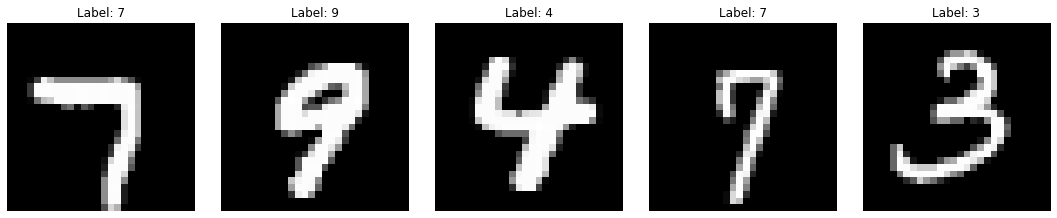

In [51]:
# Code used to import the MNIST dataset. Copied from https://www.geeksforgeeks.org/machine-learning/mnist-dataset/

import torch
import matplotlib.pyplot as plt
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import random

def load_mnist(batch_size=64):
    transform = transforms.ToTensor()
    dataset = datasets.MNIST(
        root="./data",
        train=True,
        download=True,
        transform=transform
    )
    return DataLoader(dataset, batch_size=batch_size, shuffle=True)

def visualize_samples(dataloader, num_samples=5):
    images, labels = next(iter(dataloader))

    plt.figure(figsize=(15, 3))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.title(f"Label: {labels[i].item()}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

train_loader = load_mnist(batch_size=64)
visualize_samples(train_loader)

## Model architecture

My plan is to create a model architecture that can adequately encapsulate the problem without being excessively large. Every image in the MNIST data set is a 28x28 pixel greysquare scale. My plan is to assign a numerical value to each picture and use this (28,28) matrice of numbers as the input for the network. My architecture will be as follows:

$$ 784 \rightarrow 128 \rightarrow 64 \rightarrow 10 $$

After testing with 20 neurons and reading online, it seemed more appropriate to have more neurons in the hidden layers. As such we have gone with above to achieve this aim and hope to provide enough depth to be able to effectively model the problem. After the hidden layers, there will be a ReLu function which aims to improve efficiency. NOTE: I have not used this activation functions before, I read up briefly on it and am just trying it out. Each output layer will also be an affine layer. 

Will use CrossEntropyLoss as it is the most appropriate loss for a classification task. Namely, it is used to measure how much a model's predicited probability distribution differs from the true categorical labels. Since we are trying to classify numbers, it helps to achieve this aim. We will use the classic Adam optimiser.

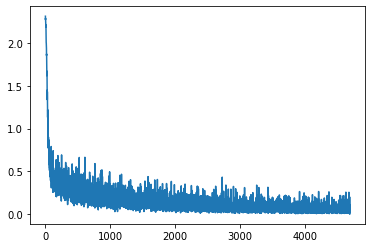

In [38]:
# Number of epochs (runs through the model)
epochs = 5

lossvalues=[]

torch.manual_seed(0)

model = nn.Sequential(
        nn.Flatten(),  # Flattens the inputs so that (batch, 1, 28, 28) -> (batch, 784)
        nn.Linear(784, 128),
        nn.ReLU(),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 10),
) 

# Loss and optimiser
loss = nn.CrossEntropyLoss()
optimiser = torch.optim.Adam(model.parameters(), lr=0.001)

# Training loop
for i in range(epochs):
    
    # Setting model to training mode
    model.train() 
    
    # Iterating over the dataset generated by train_loader
    for images, labels in train_loader:
        
        # Clearing gradient values
        optimiser.zero_grad(set_to_none=True)
        
        # Running forward pass and appending loss value to list of loss values
        predictions = model(images).squeeze(1)
        L = loss(predictions, labels)
    
        # Running the backwards pass
        L.backward()
    
        # Updates all paramaters
        optimiser.step()
        lossvalues.append(L.item())
    
plt.plot(lossvalues)

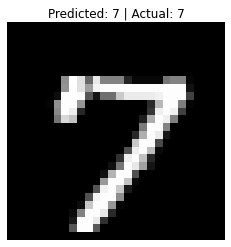

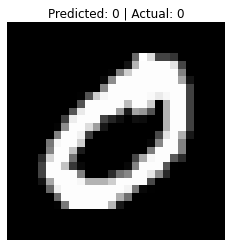

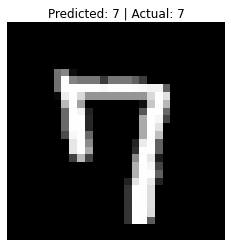

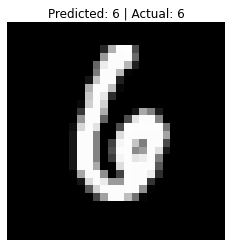

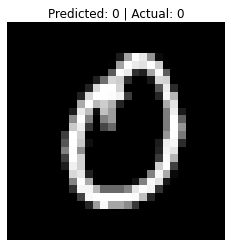

In [57]:
## Code generated from Gen AI to test my model. Seems to work well. 

for i in range(5):

    # 1. Pick a random image and label from your test dataset
    idx = random.randint(0, len(train_loader) - 1)
    image, actual_label = train_loader.dataset[idx]

    # 2. Prepare the image (add batch dimension [1, 1, 28, 28] and move to device)
    input_tensor = image.unsqueeze(0)

    # 3. Run prediction without tracking gradients
    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        predicted_label = output.argmax(dim=1).item()

    # 4. Display the result
    plt.subplots(1)
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Predicted: {predicted_label} | Actual: {actual_label}")
    plt.axis("off")
    plt.show()